# Этап 1. Профилирование `yield_df.csv`: подсчёт дефектов

Блокнот только **измеряет** дефекты, ничего не исправляет (очистка делается в `cleaning.py`).
Ожидаемые значения взяты из `dataset_description_1.md`. В конце есть сводная таблица «ожидали / получили».

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

DATA_PATH = Path("data/yield_df.csv")
KEY = ["Area", "Item", "Year"]
TARGET = "hg/ha_yield"
RAIN = "average_rain_fall_mm_per_year"
PEST = "pesticides_tonnes"
TEMP = "avg_temp"

results = {}  # сюда складываем найденные числа для итоговой таблицы

## 1. Обзор таблицы

In [2]:
df = pd.read_csv(DATA_PATH)
df = df.drop(columns="Unnamed: 0", errors="ignore")  # служебный индекс

print("Размер:", df.shape)
print("\nТипы столбцов:")
print(df.dtypes)
print("\nПропусков всего:", int(df.isna().sum().sum()))
print("Полных дубликатов строк (без служебного индекса):", int(df.duplicated().sum()))
print("\nСтран:", df["Area"].nunique(), "| культур:", df["Item"].nunique(),
      "| лет:", df["Year"].nunique(), f"({df['Year'].min()}-{df['Year'].max()})")

results["rows"] = len(df)
results["areas"] = df["Area"].nunique()
results["items"] = df["Item"].nunique()
results["years"] = df["Year"].nunique()
results["missing"] = int(df.isna().sum().sum())
results["full_duplicates"] = int(df.duplicated().sum())

df.describe().T

Размер: (28242, 7)

Типы столбцов:
Area                                 str
Item                                 str
Year                               int64
hg/ha_yield                        int64
average_rain_fall_mm_per_year    float64
pesticides_tonnes                float64
avg_temp                         float64
dtype: object

Пропусков всего: 0
Полных дубликатов строк (без служебного индекса): 2310

Стран: 101 | культур: 10 | лет: 23 (1990-2013)


,count,mean,std,min,25%,50%,75%,max
Year,28242.0,2001.544296,7.051905,1990.00,1995.0000,2001.00,2008.00,2013.00
hg/ha_yield,28242.0,77053.332094,84956.612897,50.00,19919.2500,38295.00,104676.75,501412.00
average_rain_fall_mm_per_year,28242.0,1149.055980,709.812150,51.00,593.0000,1083.00,1668.00,3240.00
pesticides_tonnes,28242.0,37076.909344,59958.784665,0.04,1702.0000,17529.44,48687.88,367778.00
avg_temp,28242.0,20.542627,6.312051,1.30,16.7025,21.51,26.00,30.65


**Замечание.** В описании набора сказано, что полностью совпадающих строк нет. Это верно только вместе со служебным
индексом `Unnamed: 0`. После его удаления полные дубликаты есть, и это следствие дефекта 2 (повторы в исходном
файле температуры), которые попали в итоговую таблицу.

## 2. Дефект 1: повтор ключа (`Area`, `Item`, `Year`)
Одна запись об урожайности не должна встречаться дважды. Проверяем, сколько строк делят ключ и чем отличаются.

In [3]:
dup_mask = df.duplicated(KEY, keep=False)
n_unique_keys = len(df.drop_duplicates(KEY))

results["rows_sharing_key"] = int(dup_mask.sum())
results["share_sharing_key"] = round(dup_mask.mean() * 100, 1)
results["unique_keys"] = n_unique_keys
results["extra_rows"] = len(df) - n_unique_keys

print(f"Строк с общим ключом: {dup_mask.sum()} ({dup_mask.mean():.1%})")
print(f"Уникальных ключей: {n_unique_keys}")
print(f"Лишних строк: {len(df) - n_unique_keys}")

Строк с общим ключом: 18949 (67.1%)
Уникальных ключей: 13130
Лишних строк: 15112


In [4]:
# Для каждого повторяющегося ключа: сколько разных значений урожайности и температуры
g = (df[dup_mask]
     .groupby(KEY)
     .agg(n_rows=(TARGET, "size"),
          n_yield=(TARGET, "nunique"),
          n_temp=(TEMP, "nunique"),
          temp_gap=(TEMP, lambda s: s.max() - s.min())))

conf_temp = g[g["n_temp"] > 1]
conf_yield = g[g["n_yield"] > 1]

results["dup_keys"] = len(g)
results["keys_temp_differs"] = len(conf_temp)
results["keys_yield_differs"] = len(conf_yield)
results["median_temp_gap"] = round(conf_temp["temp_gap"].median(), 2)

print("Повторяющихся ключей:", len(g))
print("  из них с разной температурой:", len(conf_temp))
print("  из них с одинаковой температурой (точные дубликаты):", int((g['n_temp'] == 1).sum()))
print("Ключей с разной урожайностью:", len(conf_yield))
print("Медианный разрыв температуры, °C:", round(conf_temp["temp_gap"].median(), 2))

Повторяющихся ключей: 3837
  из них с разной температурой: 3690
  из них с одинаковой температурой (точные дубликаты): 147
Ключей с разной урожайностью: 0
Медианный разрыв температуры, °C: 4.49


In [5]:
# Пример: один ключ, одна урожайность, разные температуры
example_key = conf_temp.sort_values("temp_gap", ascending=False).index[0]
df[(df[KEY] == pd.Series(example_key, index=KEY)).all(axis=1)]

,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
3400,Brazil,Sweet potatoes,1998,103928,1761.0,118930.56,22.35
3401,Brazil,Sweet potatoes,1998,103928,1761.0,118930.56,20.71
3402,Brazil,Sweet potatoes,1998,103928,1761.0,118930.56,18.20
3403,Brazil,Sweet potatoes,1998,103928,1761.0,118930.56,18.20
3404,Brazil,Sweet potatoes,1998,103928,1761.0,118930.56,28.76
3405,Brazil,Sweet potatoes,1998,103928,1761.0,118930.56,20.71
3406,Brazil,Sweet potatoes,1998,103928,1761.0,118930.56,27.54
3407,Brazil,Sweet potatoes,1998,103928,1761.0,118930.56,18.49
3408,Brazil,Sweet potatoes,1998,103928,1761.0,118930.56,26.63
3409,Brazil,Sweet potatoes,1998,103928,1761.0,118930.56,24.78


## 3. Дефект 3: «осадки» не меняются по годам

In [6]:
rain_per_area = df.groupby("Area")[RAIN].nunique()
results["areas_rain_varies"] = int((rain_per_area > 1).sum())

print("Стран, у которых осадки меняются по годам:", int((rain_per_area > 1).sum()), "из", len(rain_per_area))
print("Стран с ровно одним значением осадков за все годы:", int((rain_per_area == 1).sum()))

# Для сравнения: изменчивость по годам у других признаков внутри страны
within_area = pd.DataFrame({
    "rain": df.groupby("Area")[RAIN].nunique(),
    "temp": df.groupby("Area")[TEMP].nunique(),
    "pest": df.groupby("Area")[PEST].nunique(),
})
within_area.describe().loc[["mean", "min", "max"]]

Стран, у которых осадки меняются по годам: 0 из 101
Стран с ровно одним значением осадков за все годы: 101


,rain,temp,pest
mean,1.0,35.376238,16.762376
min,1.0,4.000000,1.000000
max,1.0,239.000000,23.000000


## 4. Дефект 5: несогласованность температуры внутри (страна, год)
Температура должна быть одной на страну и год, независимо от культуры.

In [7]:
temp_per_ay = df.groupby(["Area", "Year"])[TEMP].nunique()
bad_ay = int((temp_per_ay > 1).sum())

results["area_year_total"] = len(temp_per_ay)
results["area_year_multi_temp"] = bad_ay

print(f"Сочетаний (страна, год): {len(temp_per_ay)}")
print(f"С более чем одним значением температуры: {bad_ay} ({bad_ay / len(temp_per_ay):.1%})")

Сочетаний (страна, год): 2250
С более чем одним значением температуры: 575 (25.6%)


## 5. Дефекты 6 и 7: асимметрия и выбросы

In [8]:
results["skew_yield"] = round(df[TARGET].skew(), 2)
results["skew_pest"] = round(df[PEST].skew(), 2)

print("Асимметрия урожайности:", results["skew_yield"])
print("Асимметрия урожайности после log1p:", round(np.log1p(df[TARGET]).skew(), 2))
print("Асимметрия пестицидов:", results["skew_pest"])
print("Асимметрия пестицидов после log1p:", round(np.log1p(df[PEST]).skew(), 2))

Асимметрия урожайности: 1.79
Асимметрия урожайности после log1p: -0.05
Асимметрия пестицидов: 3.49
Асимметрия пестицидов после log1p: -1.05


In [9]:
def iqr_outlier_share(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - k * iqr) | (s > q3 + k * iqr)).mean()

outliers = (df.groupby("Item")[TARGET]
              .apply(iqr_outlier_share)
              .rename("outlier_share")
              .sort_values(ascending=False))

# Для сравнения: доля выбросов по IQR на всей таблице (без разделения по культурам)
print("Доля выбросов по IQR на всей таблице:", f"{iqr_outlier_share(df[TARGET]):.1%}")
print("\nДоля выбросов по IQR внутри культуры:")
(outliers * 100).round(1).to_frame("outlier_%")

Доля выбросов по IQR на всей таблице: 7.3%

Доля выбросов по IQR внутри культуры:


,outlier_%
Item,
Wheat,8.6
Plantains and others,7.6
Maize,5.0
Sorghum,3.9
Sweet potatoes,3.7
"Rice, paddy",3.6
Potatoes,2.7
Soybeans,0.3
Cassava,0.0


In [10]:
results["outlier_wheat"] = round(outliers["Wheat"] * 100, 1)
results["outlier_plantains"] = round(outliers["Plantains and others"] * 100, 1)
results["outlier_maize"] = round(outliers["Maize"] * 100, 1)

## 6. Перекосы выборки: страны, годы, культуры
Смотрим, насколько неравномерно распределены строки. От этого зависят метрики на всей выборке и размеры фолдов при `GroupKFold` по странам.

In [11]:
rows_by_area = df["Area"].value_counts()

results["rows_india"] = int(rows_by_area["India"])
results["share_india"] = round(rows_by_area["India"] / len(df) * 100, 1)
results["rows_montenegro"] = int(rows_by_area["Montenegro"])

def with_share(s):
    return s.to_frame("rows").assign(share_pct=(s / len(df) * 100).round(1))

print("5 стран с наибольшим числом строк:")
print(with_share(rows_by_area.head(5)))
print("\n5 стран с наименьшим числом строк:")
print(with_share(rows_by_area.tail(5)))
print(f"\nДоля пяти крупнейших стран: {rows_by_area.head(5).sum() / len(df):.1%}")
print(f"Строк на страну: медиана {rows_by_area.median():.0f}, min {rows_by_area.min()}, max {rows_by_area.max()}")
print(f"Отношение max/min: {rows_by_area.max() / rows_by_area.min():.0f}")

5 стран с наибольшим числом строк:
           rows  share_pct
Area                      
India      4048       14.3
Brazil     2277        8.1
Mexico     1472        5.2
Pakistan   1449        5.1
Australia   966        3.4

5 стран с наименьшим числом строк:
            rows  share_pct
Area                       
Latvia        42        0.1
Belgium       39        0.1
Bahrain       29        0.1
Sudan         28        0.1
Montenegro    24        0.1

Доля пяти крупнейших стран: 36.2%
Строк на страну: медиана 161, min 24, max 4048
Отношение max/min: 169


In [12]:
# Годы: есть ли пропуски в диапазоне и как строки распределены по годам
rows_by_year = df["Year"].value_counts().sort_index()
missing_years = sorted(set(range(df["Year"].min(), df["Year"].max() + 1)) - set(df["Year"].unique()))
print("Годы, отсутствующие внутри диапазона:", missing_years)
print(f"Строк в год: min {rows_by_year.min()}, max {rows_by_year.max()}")

# Покрытие по годам внутри страны (панель несбалансирована?)
years_per_area = df.groupby("Area")["Year"].nunique()
print(f"\nЛет на страну: min {years_per_area.min()}, медиана {years_per_area.median():.0f}, max {years_per_area.max()}")
print("Стран с полным набором лет:", int((years_per_area == df["Year"].nunique()).sum()), "из", len(years_per_area))

# Культуры: число строк, стран и средняя урожайность
by_item = (df.groupby("Item")
             .agg(rows=(TARGET, "size"),
                  areas=("Area", "nunique"),
                  median_yield=(TARGET, "median"))
             .sort_values("rows", ascending=False))
by_item["share_pct"] = (by_item["rows"] / len(df) * 100).round(1)
by_item

Годы, отсутствующие внутри диапазона: [2003]
Строк в год: min 1164, max 1260

Лет на страну: min 2, медиана 23, max 23
Стран с полным набором лет: 85 из 101


,rows,areas,median_yield,share_pct
Item,,,,
Potatoes,4276,95,182271.0,15.1
Maize,4121,92,25401.0,14.6
Wheat,3857,82,25497.0,13.7
"Rice, paddy",3388,68,35878.0,12.0
Soybeans,3223,58,15533.0,11.4
Sorghum,3039,67,12885.0,10.8
Sweet potatoes,2890,53,99940.0,10.2
Cassava,2045,41,128200.0,7.2
Yams,847,21,92593.0,3.0


## 7. Графики
Все рисунки сохраняются в папку `figures/` для отчёта.

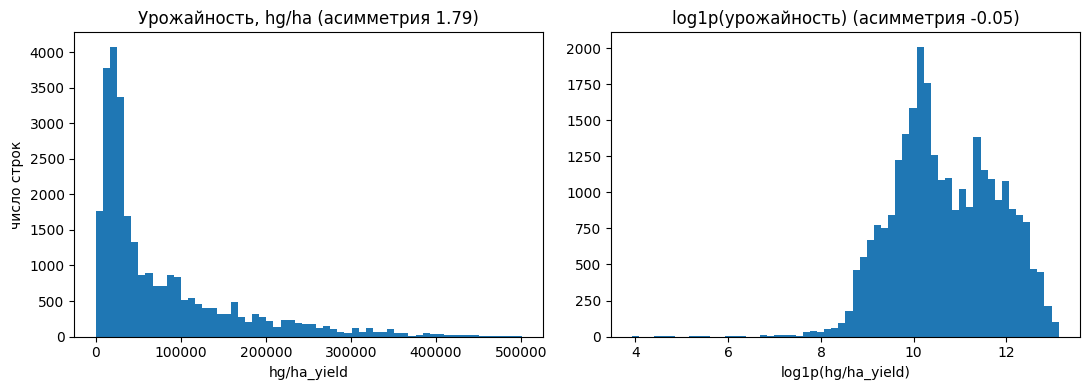

In [13]:
import matplotlib.pyplot as plt

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

def save_show(fig, name):
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()

# 7.1 Гистограмма урожайности: исходная и после log1p
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(df[TARGET], bins=60)
ax[0].set_title(f"Урожайность, hg/ha (асимметрия {results['skew_yield']})")
ax[0].set_xlabel("hg/ha_yield"); ax[0].set_ylabel("число строк")

y_log = np.log1p(df[TARGET])
ax[1].hist(y_log, bins=60)
ax[1].set_title(f"log1p(урожайность) (асимметрия {y_log.skew():.2f})")
ax[1].set_xlabel("log1p(hg/ha_yield)")
fig.tight_layout()
save_show(fig, "01_yield_hist.png")

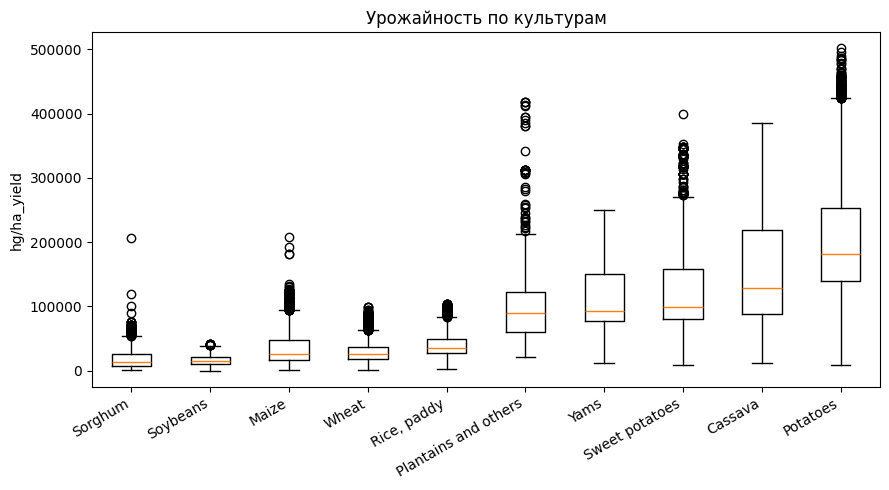

In [14]:
# 7.2 Boxplot урожайности по культурам (усы = правило IQR с k=1.5, точки за усами = выбросы)
order = df.groupby("Item")[TARGET].median().sort_values().index
fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot([df.loc[df["Item"] == i, TARGET] for i in order])
ax.set_xticklabels(order, rotation=30, ha="right")
ax.set_ylabel("hg/ha_yield")
ax.set_title("Урожайность по культурам")
fig.tight_layout()
save_show(fig, "02_yield_boxplot_by_item.png")

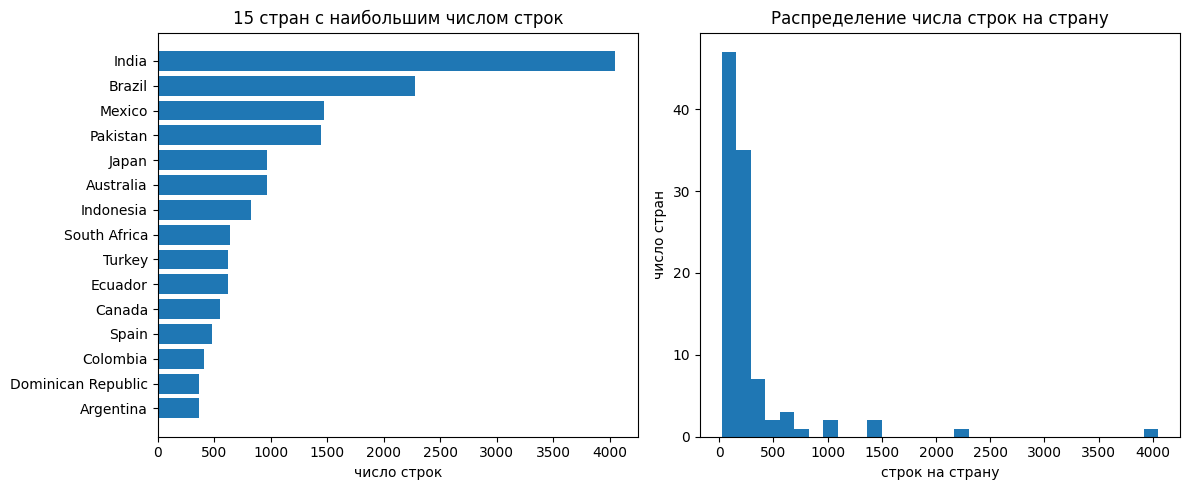

In [15]:
# 7.3 Строки по странам: 15 крупнейших и распределение числа строк на страну
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
top = rows_by_area.head(15).sort_values()
ax[0].barh(top.index, top.values)
ax[0].set_title("15 стран с наибольшим числом строк")
ax[0].set_xlabel("число строк")

ax[1].hist(rows_by_area.values, bins=30)
ax[1].set_title("Распределение числа строк на страну")
ax[1].set_xlabel("строк на страну"); ax[1].set_ylabel("число стран")
fig.tight_layout()
save_show(fig, "03_rows_by_area.png")

Пар (страна, год) с ненулевым разбросом: 575 из 2250
Медиана разброса среди них: 3.92 °C, максимум: 10.56 °C


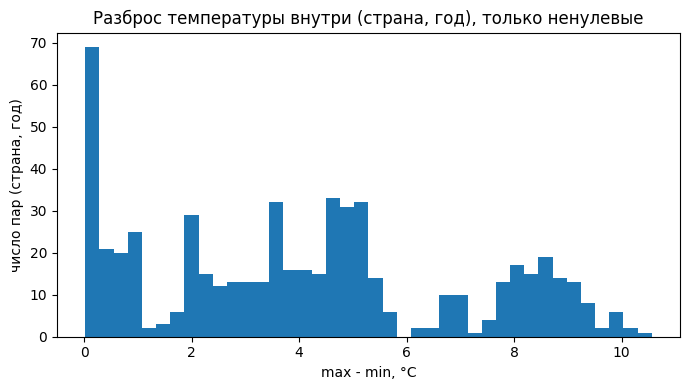

In [16]:
# 7.4 Разброс температуры внутри одной страны и одного года (должен быть 0)
temp_gap_ay = df.groupby(["Area", "Year"])[TEMP].agg(lambda s: s.max() - s.min())
nonzero_gap = temp_gap_ay[temp_gap_ay > 0]
print(f"Пар (страна, год) с ненулевым разбросом: {len(nonzero_gap)} из {len(temp_gap_ay)}")
print(f"Медиана разброса среди них: {nonzero_gap.median():.2f} °C, максимум: {nonzero_gap.max():.2f} °C")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(nonzero_gap, bins=40)
ax.set_title("Разброс температуры внутри (страна, год), только ненулевые")
ax.set_xlabel("max - min, °C"); ax.set_ylabel("число пар (страна, год)")
fig.tight_layout()
save_show(fig, "04_temp_gap_within_area_year.png")

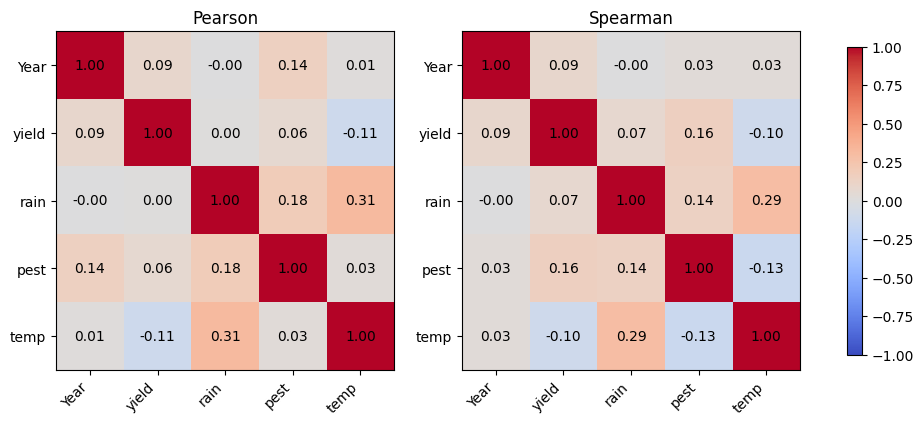

In [17]:
# 7.5 Корреляции числовых признаков (Пирсон и Спирмен)
num_cols = ["Year", TARGET, RAIN, PEST, TEMP]
short = {"Year": "Year", TARGET: "yield", RAIN: "rain", PEST: "pest", TEMP: "temp"}
labels = [short[c] for c in num_cols]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    corr = df[num_cols].corr(method=method)
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45, ha="right")
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
    ax.set_title(method.capitalize())
fig.colorbar(im, ax=axes, shrink=0.8)
save_show(fig, "05_correlations.png")

**Как читать корреляции.** `rain` постоянна внутри страны (дефект 3), поэтому её связь с урожайностью отражает различия **между странами**, а не влияние осадков по годам. Корреляция Спирмена устойчивее к скошенным распределениям (дефекты 6 и 7), чем Пирсона.

## 8. Сводная таблица дефектов: масштаб и влияние на модель
Дефекты 2 и 4 относятся к сырым файлам `temp.csv` и `rainfall.csv`, которые в работе не используются. В таблицу они не включены, в тексте на них ссылаемся на `dataset_description_1.md` (раздел 3). Дефект 8 это перекос выборки из раздела 6, в описании набора он не пронумерован.

In [18]:
r = results
defects = pd.DataFrame([
    {"№": 1, "Дефект": "Размножение строк при объединении: повтор ключа (Area, Item, Year)",
     "Масштаб": f"{r['rows_sharing_key']} строк ({r['share_sharing_key']} %) делят ключ; лишних строк {r['extra_rows']}; "
                f"{r['keys_temp_differs']} ключей с разной температурой",
     "Влияние на модель": "Копии одной записи попадают и в train, и в test при случайном разбиении: метрики завышены. "
                          "Для ключей с разной температурой признак зашумлён."},
    {"№": 3, "Дефект": "Осадки постоянны внутри страны",
     "Масштаб": f"у {r['areas'] - r['areas_rain_varies']} из {r['areas']} стран одно значение за все годы",
     "Влияние на модель": "Признак работает как идентификатор страны, а не климатический фактор. "
                          "Завышает метрики при случайной валидации, бесполезен при GroupKFold, искажает важность признаков."},
    {"№": 5, "Дефект": "Несколько значений температуры у одной пары (страна, год)",
     "Масштаб": f"{r['area_year_multi_temp']} из {r['area_year_total']} пар ({r['area_year_multi_temp'] / r['area_year_total']:.1%}); "
                f"медианный разрыв {r['median_temp_gap']} °C",
     "Влияние на модель": "Шум в признаке: один и тот же объект описан разными температурами. Ограничивает достижимую точность."},
    {"№": 6, "Дефект": "Асимметрия целевой переменной и выбросы",
     "Масштаб": f"асимметрия {r['skew_yield']}; выбросы по IQR: пшеница {r['outlier_wheat']} %, "
                f"плантаны {r['outlier_plantains']} %, кукуруза {r['outlier_maize']} %",
     "Влияние на модель": "RMSE определяется редкими большими значениями. Ridge и MLP хуже работают на скошенной цели; "
                          "возможна замена на log1p с обратным преобразованием."},
    {"№": 7, "Дефект": "Скошенное распределение пестицидов",
     "Масштаб": f"асимметрия {r['skew_pest']}",
     "Влияние на модель": "Влияет на линейные модели и MLP (масштаб признака); деревья нечувствительны. Нужен log1p внутри Pipeline."},
    {"№": "8 (доп.)", "Дефект": "Перекос выборки по странам",
     "Масштаб": f"Индия {r['rows_india']} строк ({r['share_india']} %), Черногория {r['rows_montenegro']}",
     "Влияние на модель": "Метрики на всей выборке определяются крупными странами; при GroupKFold фолды получаются разного размера."},
])

pd.set_option("display.max_colwidth", None)
defects.to_csv(FIG_DIR / "defects_table.csv", index=False, encoding="utf-8-sig")
defects

,№,Дефект,Масштаб,Влияние на модель
0,1,"Размножение строк при объединении: повтор ключа (Area, Item, Year)",18949 строк (67.1 %) делят ключ; лишних строк 15112; 3690 ключей с разной температурой,"Копии одной записи попадают и в train, и в test при случайном разбиении: метрики завышены. Для ключей с разной температурой признак зашумлён."
1,3,Осадки постоянны внутри страны,у 101 из 101 стран одно значение за все годы,"Признак работает как идентификатор страны, а не климатический фактор. Завышает метрики при случайной валидации, бесполезен при GroupKFold, искажает важность признаков."
2,5,"Несколько значений температуры у одной пары (страна, год)",575 из 2250 пар (25.6%); медианный разрыв 4.49 °C,Шум в признаке: один и тот же объект описан разными температурами. Ограничивает достижимую точность.
3,6,Асимметрия целевой переменной и выбросы,"асимметрия 1.79; выбросы по IQR: пшеница 8.6 %, плантаны 7.6 %, кукуруза 5.0 %",RMSE определяется редкими большими значениями. Ridge и MLP хуже работают на скошенной цели; возможна замена на log1p с обратным преобразованием.
4,7,Скошенное распределение пестицидов,асимметрия 3.49,Влияет на линейные модели и MLP (масштаб признака); деревья нечувствительны. Нужен log1p внутри Pipeline.
5,8 (доп.),Перекос выборки по странам,"Индия 4048 строк (14.3 %), Черногория 24",Метрики на всей выборке определяются крупными странами; при GroupKFold фолды получаются разного размера.


## Сводка: ожидали / получили

In [19]:
expected = {
    "rows": 28242, "areas": 101, "items": 10, "years": 23, "missing": 0,
    "rows_sharing_key": 18949, "share_sharing_key": 67.1, "unique_keys": 13130, "extra_rows": 15112,
    "keys_temp_differs": 3690, "keys_yield_differs": 0, "median_temp_gap": 4.2,
    "areas_rain_varies": 0, "area_year_total": 2250, "area_year_multi_temp": 575,
    "skew_yield": 1.79, "skew_pest": 3.49,
    "outlier_wheat": 8.6, "outlier_plantains": 7.6, "outlier_maize": 5.0,
    "rows_india": 4048, "share_india": 14.3, "rows_montenegro": 24,
    "full_duplicates": 0,
}
summary = pd.DataFrame({
    "ожидали (описание)": pd.Series(expected),
    "получили": pd.Series(results).reindex(list(expected)),
})
summary["совпало"] = (summary["ожидали (описание)"] - summary["получили"]).abs() < 0.05
summary

,ожидали (описание),получили,совпало
rows,28242.00,28242.00,True
areas,101.00,101.00,True
items,10.00,10.00,True
years,23.00,23.00,True
missing,0.00,0.00,True
rows_sharing_key,18949.00,18949.00,True
share_sharing_key,67.10,67.10,True
unique_keys,13130.00,13130.00,True
extra_rows,15112.00,15112.00,True
keys_temp_differs,3690.00,3690.00,True


**Два расхождения с описанием:**
- `full_duplicates`: описание говорит об отсутствии полных дубликатов, но это верно только с учётом столбца `Unnamed: 0`. Без него таких строк 2 310.
- `median_temp_gap`: получилось 4,49 °C вместо ~4,2 °C. Вероятно, в описании разрыв считался иначе (например, по парам значений, а не max - min по ключу). Для работы это несущественно, но в тексте лучше указывать своё число.